In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [34]:
import pandas as pd
df =pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [35]:
df.shape


(891, 12)

In [36]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [37]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [38]:
df.describe(include="object")

C:\Users\DELL\AppData\Local\Temp\ipykernel_22756\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [39]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [40]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [41]:
df["Pclass"].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [42]:
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [43]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [44]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [45]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [46]:
df["Cabin"] = df["Cabin"].fillna("Unknown")

In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [49]:
df["Has_Cabin"] = (df["Cabin"] != "Unknown").astype(int)

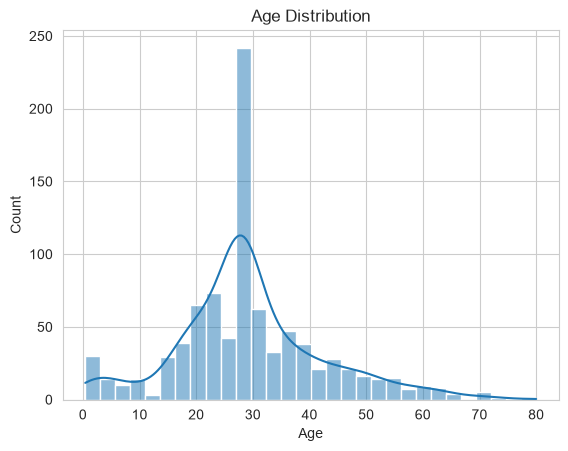

In [50]:
sns.histplot(df["Age"], kde=True); plt.title("Age Distribution"); plt.savefig("images/age_hist.png"); plt.show()

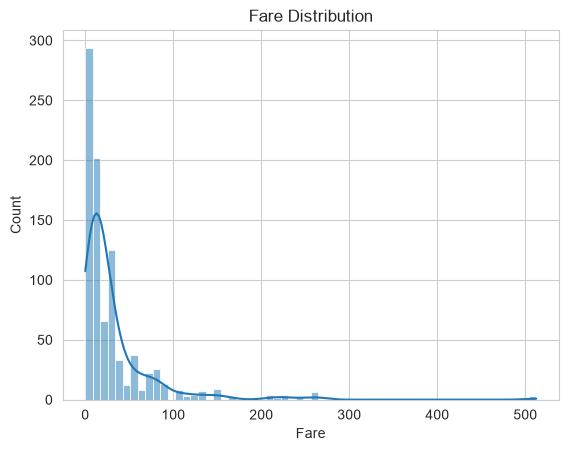

In [51]:
sns.histplot(df["Fare"], kde=True); plt.title("Fare Distribution"); plt.savefig("images/fare_hist.png"); plt.show()

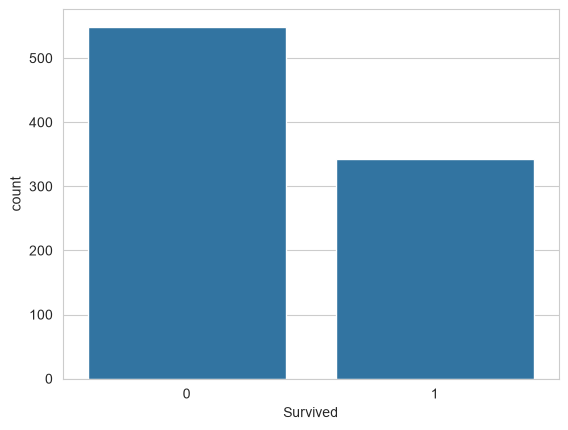

In [52]:
sns.countplot(x="Survived", data=df); plt.savefig("images/survived_count.png"); plt.show()

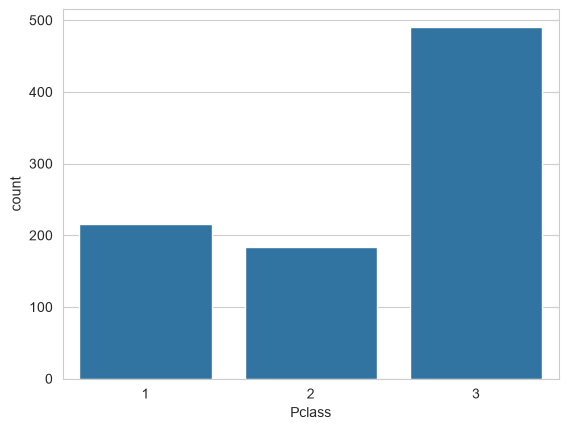

In [53]:
sns.countplot(x="Pclass", data=df); plt.savefig("images/pclass_count.png"); plt.show()

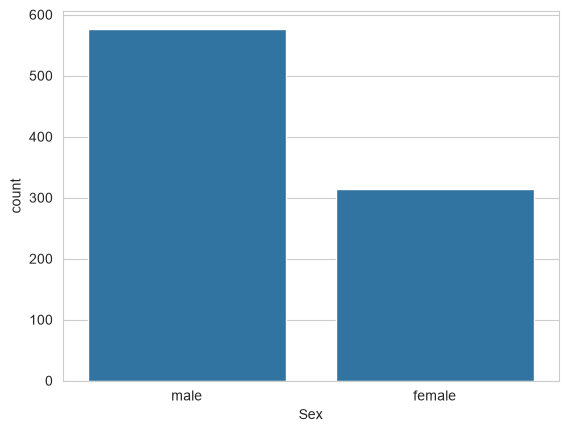

In [54]:
sns.countplot(x="Sex", data=df); plt.savefig("images/sex_count.png"); plt.show()

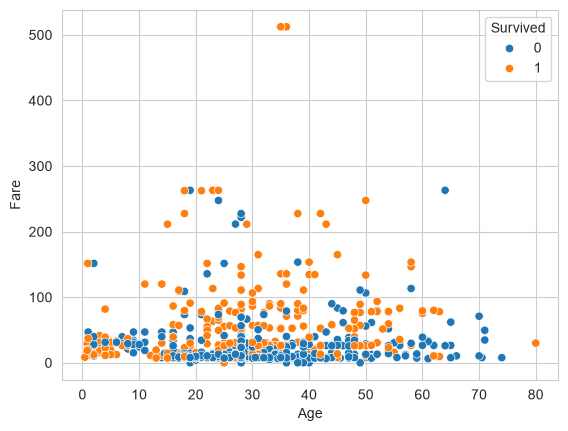

In [55]:
sns.scatterplot(x="Age", y="Fare", hue="Survived", data=df); plt.savefig("images/scatter_age_fare.png"); plt.show()

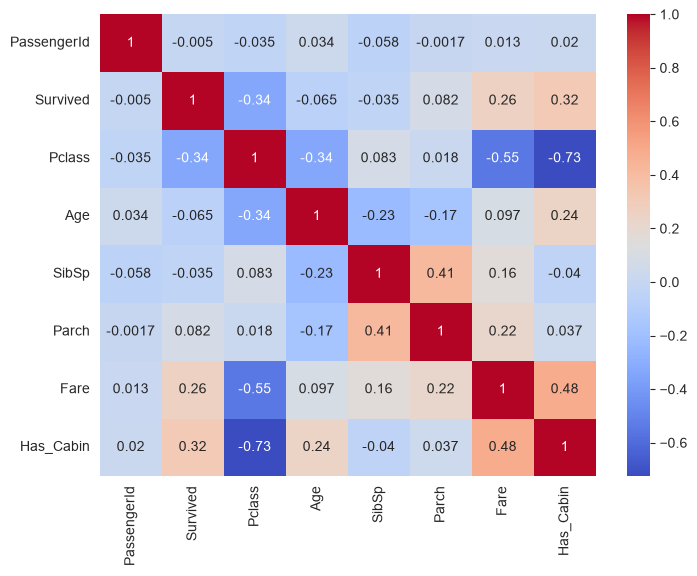

In [56]:
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm")
plt.savefig("images/heatmap.png"); plt.show()

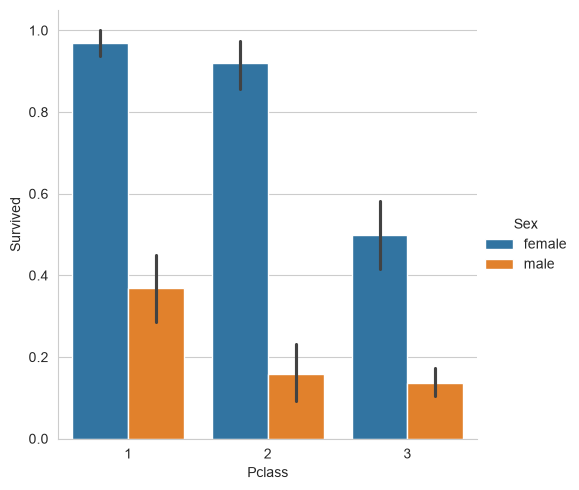

In [57]:
sns.catplot(kind="bar", x="Pclass", y="Survived", hue="Sex", data=df)
plt.savefig("images/surv_class_sex.png"); plt.show()